# Chương 6. Vector hóa văn bản và phân tích không gian đặc trưng

So sánh BoW, TF-IDF (n-gram 1–3), Word2Vec và [Nâng cao] Sentence Transformer theo: số chiều, độ thưa, cosine similarity trong/giữa lớp, t-SNE và silhouette score.

**Nguyên tắc của chương.**
- Mọi thứ cần học từ dữ liệu (từ vựng và IDF của BoW/TF-IDF, mô hình Word2Vec, phép giảm chiều SVD) **chỉ fit trên tập train**. Hình học của các biểu diễn (cosine, silhouette, t-SNE) được đo trên **toàn bộ tập test** (9.916 review, ít hơn `config.TEXT_SAMPLE_SIZE`), tức trên dữ liệu mà các biểu diễn chưa từng thấy.
- Biểu diễn thưa và Word2Vec dùng cột `clean` của chương 5; Sentence Transformer dùng cột `light` (văn bản tự nhiên, còn chữ hoa và dấu câu).
- "n-gram $n\in\{1,2,3\}$" được hiểu là dải $(1,n)$: $n=2$ gồm cả unigram và bigram, $n=3$ gồm unigram, bigram và trigram.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from dmprep import config
import hashlib
import os
import time

from scipy import sparse, stats
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize


config.set_seed()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 4)

RESULTS: dict = {}  # mọi score / p-value của chương này được lưu vào đây

In [2]:
clean_path = config.PROCESSED_DIR / "imdb_clean.parquet"
if not clean_path.exists():
    raise FileNotFoundError("Chưa có imdb_clean.parquet: hãy chạy chương 5 (mục 5.5) trước.")
df = pd.read_parquet(clean_path)
train, test = df[df["split"] == "train"].reset_index(drop=True), df[df["split"] == "test"].reset_index(drop=True)
y_train, y_test = train["label"].to_numpy(), test["label"].to_numpy()
assert len(test) <= config.TEXT_SAMPLE_SIZE  # test đủ nhỏ để dùng toàn bộ cho các phép tính nặng

# Mẫu có nhãn dùng để huấn luyện bộ phân loại ở mục 6.4 (phân tầng, cỡ config.TEXT_SAMPLE_SIZE)
sub_idx = train.groupby("label", group_keys=False).sample(n=config.TEXT_SAMPLE_SIZE // 2, random_state=config.SEED).index.to_numpy()
print(f"Train {len(train)}, test {len(test)} (hình học đo trên toàn bộ test), mẫu có nhãn để huấn luyện bộ phân loại: {len(sub_idx)}")
print("Ví dụ cột clean:", train["clean"].iloc[0][:100], "...")
RESULTS.update({"n_train": len(train), "n_test": len(test), "n_labeled_subset": len(sub_idx)})

Train 39662, test 9916 (hình học đo trên toàn bộ test), mẫu có nhãn để huấn luyện bộ phân loại: 10000
Ví dụ cột clean: one reviewers mentioned watching oz episode hooked right exactly happened first thing struck oz brut ...


## 6.1 BoW, TF-IDF và Word2Vec

**BoW (bag-of-words).** Mỗi review là vector đếm số lần xuất hiện của từng từ trong từ vựng (bỏ thứ tự từ).

**TF-IDF.** Giảm trọng số của các từ xuất hiện ở nhiều review. Với từ $t$ và review $d$ (cài đặt mặc định của scikit-learn):
$$\text{tf-idf}(t,d) = \text{tf}(t,d)\cdot\left(\ln\frac{1+N}{1+\text{df}(t)} + 1\right)$$
với $N$ là số review của train, $\text{df}(t)$ là số review chứa $t$; sau đó mỗi hàng được chuẩn hóa L2. Ta thử ba dải n-gram: $(1,1)$, $(1,2)$ và $(1,3)$, và cả BoW $(1,1)$ làm mốc. Tất cả dùng `min_df=5` (bỏ từ hoặc n-gram xuất hiện ở dưới 5 review, vì chương 4 cho thấy 41% từ vựng chỉ xuất hiện một lần) để các cấu hình so sánh công bằng và số chiều không bùng nổ.

**Word2Vec (skip-gram).** Học vector dày đặc $v_w$ cho từng từ bằng cách dự đoán các từ ngữ cảnh quanh một từ giữa: tối đa hóa $\sum_{t}\sum_{-c\le j\le c,\,j\ne0}\ln P(w_{t+j}\mid w_t)$, xấp xỉ bằng lấy mẫu âm (5 mẫu âm). Các từ xuất hiện trong ngữ cảnh giống nhau có vector gần nhau. Ta huấn luyện **trên chính tập train** (cửa sổ 5, `min_count=5`, 100 chiều, 5 epoch). Để tái lập được, ta dùng `workers=1`, seed cố định và hàm băm xác định (hàm băm mặc định của Python thay đổi theo từng lần chạy). **Vector của một review** là trung bình các vector của những từ có trong từ vựng Word2Vec; review không có từ nào trong từ vựng nhận vector 0.

**Độ thưa.** $\text{sparsity}=1-\dfrac{\text{nnz}}{n_{\text{docs}}\times n_{\text{dims}}}$, với nnz là số phần tử khác 0 (tính trên ma trận test). Biểu diễn dày đặc (Word2Vec) có độ thưa gần 0.

In [3]:
def stable_hash(s: str) -> int:
    return int(hashlib.md5(s.encode()).hexdigest(), 16) % 2 ** 32


VECTORIZERS = {
    "BoW (1-gram)": CountVectorizer(min_df=5),
    "TF-IDF (1-gram)": TfidfVectorizer(min_df=5),
    "TF-IDF (1-2 gram)": TfidfVectorizer(min_df=5, ngram_range=(1, 2)),
    "TF-IDF (1-3 gram)": TfidfVectorizer(min_df=5, ngram_range=(1, 3)),
}
REP_TRAIN, REP_TEST, rows = {}, {}, {}
for name, vec in VECTORIZERS.items():
    t0 = time.time()
    REP_TRAIN[name] = vec.fit_transform(train["clean"])  # chỉ fit trên train
    REP_TEST[name] = vec.transform(test["clean"])
    X = REP_TEST[name]
    rows[name] = {"số chiều": X.shape[1], "nnz / review": X.nnz / X.shape[0], "sparsity ratio": 1 - X.nnz / (X.shape[0] * X.shape[1]), "thời gian fit (s)": time.time() - t0}

from gensim.models import Word2Vec

t0 = time.time()
w2v = Word2Vec(sentences=[s.split() for s in train["clean"]], vector_size=100, window=5, min_count=5, sg=1, epochs=5, workers=1, seed=config.SEED, hashfxn=stable_hash)
w2v_time = time.time() - t0


def doc_vectors(texts: pd.Series) -> np.ndarray:
    """Trung bình vector các từ có trong từ vựng Word2Vec; review không có từ nào nhận vector 0."""
    out = np.zeros((len(texts), w2v.vector_size), dtype=np.float32)
    for i, s in enumerate(texts):
        vecs = [w2v.wv[w] for w in s.split() if w in w2v.wv]
        if vecs:
            out[i] = np.mean(vecs, axis=0)
    return out


REP_TRAIN["Word2Vec (trung bình)"], REP_TEST["Word2Vec (trung bình)"] = doc_vectors(train["clean"]), doc_vectors(test["clean"])
W = REP_TEST["Word2Vec (trung bình)"]
rows["Word2Vec (trung bình)"] = {"số chiều": W.shape[1], "nnz / review": np.count_nonzero(W) / W.shape[0], "sparsity ratio": 1 - np.count_nonzero(W) / W.size, "thời gian fit (s)": w2v_time}
n_zero_docs = int((np.abs(W).sum(axis=1) == 0).sum())
rep_table = pd.DataFrame(rows).T
display(rep_table.round(6))
print(f"Word2Vec: từ vựng {len(w2v.wv):,} từ; review test không có từ nào trong từ vựng: {n_zero_docs}")
print("Láng giềng gần nhất trong không gian Word2Vec (cosine):")
neighbors = {w: [x for x, _ in w2v.wv.most_similar(w, topn=5)] for w in ["good", "bad", "terrible", "boring", "excellent"]}
for w, nb_ in neighbors.items():
    print(f"  {w}: {nb_}")
RESULTS.update({"rep_table": rep_table.round(8).to_dict("index"), "w2v_vocab": len(w2v.wv), "w2v_zero_docs_test": n_zero_docs, "w2v_neighbors": neighbors})

,số chiều,nnz / review,sparsity ratio,thời gian fit (s)
BoW (1-gram),32951.0,96.999697,0.997056,5.047045
TF-IDF (1-gram),32951.0,96.999697,0.997056,5.754819
TF-IDF (1-2 gram),143441.0,135.994554,0.999052,16.580556
TF-IDF (1-3 gram),158199.0,138.973981,0.999122,21.568361
Word2Vec (trung bình),100.0,100.000000,0.000000,142.369809


Word2Vec: từ vựng 36,875 từ; review test không có từ nào trong từ vựng: 0
Láng giềng gần nhất trong không gian Word2Vec (cosine):
  good: ['decent', 'great', 'bad', 'downsides', 'godawful']
  bad: ['terrible', 'awful', 'horrible', 'lousy', 'good']
  terrible: ['horrible', 'awful', 'horrendous', 'abysmal', 'lousy']
  boring: ['tedious', 'dull', 'uneventful', 'pointless', 'uninteresting']
  excellent: ['outstanding', 'superb', 'terrific', 'fantastic', 'great']


**Phân tích kết quả.**

| Biểu diễn | Số chiều | nnz / review | Độ thưa | Thời gian fit |
|---|---|---|---|---|
| BoW (1-gram) | 32.951 | 97.0 | 0.997056 | 3.7 s |
| TF-IDF (1-gram) | 32.951 | 97.0 | 0.997056 | 3.9 s |
| TF-IDF (1-2 gram) | 143.441 | 136.0 | 0.999052 | 12.0 s |
| TF-IDF (1-3 gram) | 158.199 | 139.0 | 0.999122 | 20.6 s |
| Word2Vec (trung bình) | 100 | 100 | 0 | 159.4 s |

- **Số chiều, độ thưa và chi phí.** BoW và TF-IDF 1-gram có cùng số chiều và cùng độ thưa (chỉ khác cách đặt trọng số). Thêm bigram làm số chiều tăng 4.4 lần (32.951 lên 143.441) nhưng số phần tử khác 0 mỗi review chỉ tăng từ 97 lên 136, vì với `min_df=5` chỉ các cặp từ phổ biến được giữ. **Thêm trigram gần như không thay đổi gì**: chỉ thêm 14.758 chiều và 3 phần tử khác 0 mỗi review, tức rất ít bộ ba từ xuất hiện ở từ 5 review trở lên. Vì thế biểu diễn $(1,3)$ gần như trùng với $(1,2)$ trong thực tế. Mọi biểu diễn TF-IDF đều cực thưa (trên 99.7% phần tử bằng 0). Word2Vec chỉ có 100 chiều, hoàn toàn dày đặc (độ thưa 0), nhưng tốn công huấn luyện nhất (159 s so với vài giây).
- **Word2Vec nắm được tương đồng ngữ nghĩa mà BoW/TF-IDF không có.** Láng giềng gần nhất của *terrible* là *horrible, awful, horrendous, abysmal, lousy*; của *excellent* là *outstanding, superb, terrific, fantastic, great*; của *boring* là *tedious, dull, uneventful, pointless*. Trong BoW và TF-IDF, hai từ khác nhau luôn trực giao (cosine bằng 0) dù đồng nghĩa.
- **Nhưng "tương đồng" của Word2Vec là tương đồng về ngữ cảnh, không phải về cực tính cảm xúc.** Láng giềng của *good* gồm *decent, great* nhưng cũng có **bad**, và láng giềng của *bad* có *good*: hai từ trái nghĩa xuất hiện trong ngữ cảnh rất giống nhau ("a good/bad movie") nên có vector gần nhau. Vector review là trung bình các vector từ nên còn mất thứ tự từ (không phân biệt "not good" và "good").
- **Đánh đổi.** TF-IDF: số chiều lớn, rất thưa, khớp từ chính xác, không có ngữ nghĩa nhưng huấn luyện gần như tức thì; Word2Vec: nhỏ gọn, có ngữ nghĩa từ vựng, nhưng mất thứ tự và phủ định, và phải huấn luyện. Cả hai đều chỉ fit trên train.

## 6.2 Cosine similarity trong lớp và giữa các lớp

Độ tương đồng cosine giữa hai vector: $\cos(x,y)=\dfrac{x\cdot y}{\lVert x\rVert\,\lVert y\rVert}$. Một biểu diễn "tốt" cho bài toán cảm xúc nên có cosine **cùng lớp** cao hơn cosine **khác lớp**.

**Cách đo.** Ta chia ngẫu nhiên (seed cố định) toàn bộ tập test thành 10 tập con có kích thước gần bằng nhau (khoảng 990 review). Trong **mỗi tập con** ta tính cosine của *mọi* cặp review khác nhau (khoảng 490 nghìn cặp) rồi lấy trung bình cho nhóm cặp cùng lớp và nhóm cặp khác lớp. Cách này không cần lấy mẫu cặp và cho độ biến thiên giữa các tập con. Với mỗi biểu diễn ta báo:
- $\bar c_{\text{same}}$, $\bar c_{\text{diff}}$ và chênh lệch $\Delta=\bar c_{\text{same}}-\bar c_{\text{diff}}$;
- **effect size Cohen** $d=\dfrac{\Delta}{s_p}$, với $s_p$ là độ lệch chuẩn gộp của cosine ở hai nhóm cặp (đơn vị: độ lệch chuẩn).

**Vì sao dùng $d$ chứ không dùng giá trị cosine thô để so sánh biểu diễn?** Mức cosine nền khác nhau rất nhiều giữa các biểu diễn (vector trung bình Word2Vec thường rất giống nhau, cosine nền cao; vector TF-IDF thưa thì cosine nền thấp). Chỉ $\Delta$ chuẩn hóa theo độ phân tán ($d$) mới so sánh được. Ta không báo p-value vì các cặp dùng chung review nên không độc lập (p-value sẽ quá nhỏ một cách vô nghĩa); độ biến thiên giữa 10 tập con là thước đo bất định thay thế.

,cos cùng lớp (TB),cos khác lớp (TB),Δ (TB),Cohen d (TB),SD(Δ) giữa 10 tập,SD(d) giữa 10 tập
BoW (1-gram),0.10198,0.09670,0.00529,0.08322,0.00064,0.00999
TF-IDF (1-gram),0.02832,0.02593,0.00239,0.12424,0.00018,0.00811
TF-IDF (1-2 gram),0.01602,0.01461,0.00142,0.13093,0.00007,0.00609
TF-IDF (1-3 gram),0.01539,0.01402,0.00136,0.13057,0.00007,0.00574
Word2Vec (trung bình),0.92654,0.92075,0.00579,0.19049,0.00047,0.01595


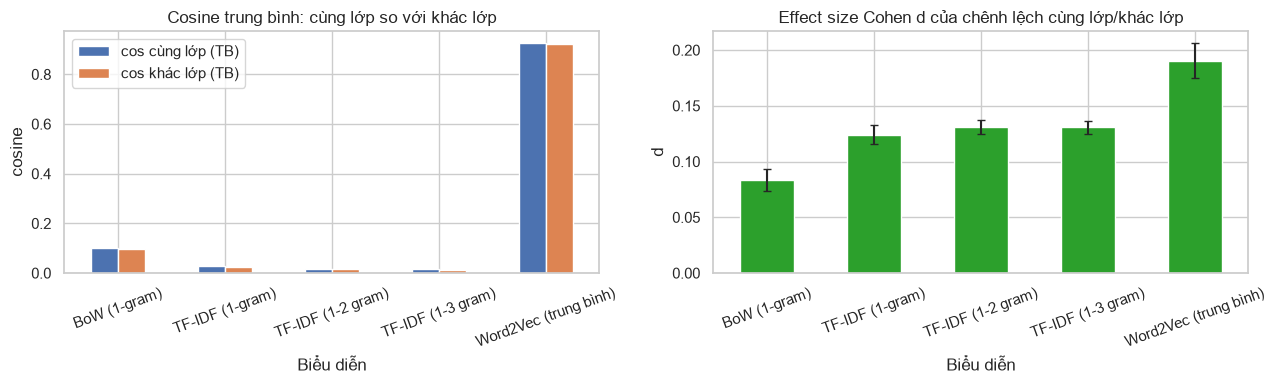

In [4]:
def within_subset_cosine(X, subset: np.ndarray) -> dict:
    """Cosine của mọi cặp trong một tập con: trung bình cùng lớp / khác lớp và Cohen d."""
    Xn = normalize(X[subset])
    S = (Xn @ Xn.T)
    S = S.toarray() if sparse.issparse(S) else S
    yy = y_test[subset]
    upper = np.triu(np.ones_like(S, dtype=bool), k=1)
    same = upper & (yy[:, None] == yy[None, :])
    diff = upper & (yy[:, None] != yy[None, :])
    cs, cd = S[same], S[diff]
    pooled = np.sqrt(((len(cs) - 1) * cs.var(ddof=1) + (len(cd) - 1) * cd.var(ddof=1)) / (len(cs) + len(cd) - 2))
    return {"cos cùng lớp": cs.mean(), "cos khác lớp": cd.mean(), "Δ": cs.mean() - cd.mean(), "Cohen d": (cs.mean() - cd.mean()) / pooled}


folds = np.array_split(np.random.default_rng(config.SEED).permutation(len(test)), 10)
cos_rows = {}
for name, X in REP_TEST.items():
    per_fold = pd.DataFrame([within_subset_cosine(X, f) for f in folds])
    cos_rows[name] = {**{f"{k} (TB)": per_fold[k].mean() for k in per_fold}, "SD(Δ) giữa 10 tập": per_fold["Δ"].std(ddof=1), "SD(d) giữa 10 tập": per_fold["Cohen d"].std(ddof=1)}
cos_table = pd.DataFrame(cos_rows).T
display(cos_table.round(5))
RESULTS["cosine_table"] = cos_table.round(8).to_dict("index")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
cos_table[["cos cùng lớp (TB)", "cos khác lớp (TB)"]].plot.bar(ax=axes[0], rot=20)
axes[0].set_title("Cosine trung bình: cùng lớp so với khác lớp"); axes[0].set_ylabel("cosine"); axes[0].set_xlabel("Biểu diễn")
cos_table["Cohen d (TB)"].plot.bar(ax=axes[1], rot=20, color="tab:green", yerr=cos_table["SD(d) giữa 10 tập"], capsize=3)
axes[1].set_title("Effect size Cohen d của chênh lệch cùng lớp/khác lớp"); axes[1].set_ylabel("d"); axes[1].set_xlabel("Biểu diễn")
plt.tight_layout()
plt.show()

**Phân tích kết quả** (10 tập con của tập test, mỗi tập khoảng 990 review).

| Biểu diễn | cosine cùng lớp | cosine khác lớp | $\Delta$ | Cohen $d$ ± SD giữa 10 tập |
|---|---|---|---|---|
| BoW (1-gram) | 0.10198 | 0.09670 | 0.00529 | 0.0832 ± 0.0100 |
| TF-IDF (1-gram) | 0.02832 | 0.02593 | 0.00239 | 0.1242 ± 0.0081 |
| TF-IDF (1-2 gram) | 0.01602 | 0.01461 | 0.00142 | 0.1309 ± 0.0061 |
| TF-IDF (1-3 gram) | 0.01539 | 0.01402 | 0.00136 | 0.1306 ± 0.0057 |
| Word2Vec (trung bình) | 0.92654 | 0.92075 | 0.00579 | **0.1905 ± 0.0160** |
| Sentence Transformer (6.4) | 0.2978 | 0.2870 | 0.0108 | 0.1016 ± 0.0131 |

- **Giá trị cosine thô không so sánh được giữa các biểu diễn.** Mức nền khác nhau rất xa: 0.016 đến 0.028 với TF-IDF (vector thưa, hai review hiếm khi chung nhiều từ), 0.10 với BoW, khoảng 0.29 với Sentence Transformer và tới 0.93 với Word2Vec (trung bình vector từ làm mọi review giống nhau). Vì vậy ta so sánh bằng Cohen $d$, đã chuẩn hóa theo độ phân tán.
- **Cả sáu biểu diễn đều có cosine cùng lớp cao hơn khác lớp, nhưng chênh lệch rất nhỏ** (Cohen $d$ từ 0.08 đến 0.19, đều dưới ngưỡng 0.2 thường gọi là "nhỏ"). Tức độ tương đồng giữa hai review chủ yếu do **chủ đề, thể loại và từ vựng** quyết định chứ không phải do cảm xúc: hai review phim kinh dị trái cảm xúc vẫn giống nhau hơn một review kinh dị và một review hài cùng cảm xúc.
- **Word2Vec cho $d$ lớn nhất (0.1905)**, hơn TF-IDF (1-2 gram) khoảng 0.060, tức khoảng 3.7 lần độ biến thiên giữa các tập con (SD = 0.0160), nên khác biệt này khá vững. Giải thích hợp lý (chưa kiểm chứng riêng): trung bình hóa vector từ khuếch đại các từ cảm xúc xuất hiện ở khắp review.
- **TF-IDF tốt hơn BoW** ($d$ = 0.1242 so với 0.0832, tăng khoảng 49%) vì IDF giảm trọng số các từ phổ biến vốn chi phối cosine của vector đếm thô. **Thêm n-gram chỉ cải thiện rất ít:** $(1,2)$ cho 0.1309 và $(1,3)$ cho 0.1306, chênh so với 1-gram (0.0067 và 0.0064) cùng bậc với độ biến thiên giữa các tập con (0.006 đến 0.008), nên ta không kết luận được n-gram có tốt hơn. Điều này nhất quán với 6.1: trigram gần như không thêm thông tin vì quá hiếm.
- **Không báo p-value** vì các cặp review dùng chung tài liệu nên không độc lập; độ biến thiên giữa 10 tập con là thước đo bất định thay thế, và đây chỉ là so sánh mô tả.

## 6.3 Trực quan t-SNE và silhouette score

**Silhouette.** Với review $i$, gọi $a(i)$ là khoảng cách cosine trung bình tới các review **cùng lớp** và $b(i)$ là khoảng cách trung bình tới các review **lớp kia**:
$$s(i)=\frac{b(i)-a(i)}{\max\{a(i),\,b(i)\}}\in[-1,1]$$
Silhouette là trung bình của $s(i)$ trên toàn bộ review, coi nhãn cảm xúc là nhãn cụm. Gần $+1$: các lớp tách rời rõ; gần 0: các lớp chồng lấn; âm: nhiều review gần lớp kia hơn lớp của mình. Ta tính trên **không gian gốc** của từng biểu diễn (khoảng cách cosine), không tính trên không gian 2D của t-SNE vì t-SNE làm méo khoảng cách.

**t-SNE** ($t$-distributed Stochastic Neighbor Embedding) chiếu dữ liệu xuống 2 chiều sao cho các điểm gần nhau trong không gian gốc vẫn gần nhau; chỉ cấu trúc *lân cận cục bộ* có ý nghĩa, còn khoảng cách giữa các đám và kích thước đám thì không. Với ma trận thưa ta giảm chiều trước bằng **TruncatedSVD 50 chiều, fit trên 10.000 review train** (chỉ dùng train), rồi chuẩn hóa L2 và chạy t-SNE (perplexity 30, khởi tạo PCA, seed cố định) trên toàn bộ tập test. Vì t-SNE chỉ dùng để quan sát nên kết luận chính dựa vào silhouette và cosine.

t-SNE BoW (1-gram): 24s | silhouette (cosine, không gian gốc) = 0.0060


t-SNE TF-IDF (1-gram): 22s | silhouette (cosine, không gian gốc) = 0.0025


t-SNE TF-IDF (1-2 gram): 25s | silhouette (cosine, không gian gốc) = 0.0014


t-SNE TF-IDF (1-3 gram): 30s | silhouette (cosine, không gian gốc) = 0.0014


t-SNE Word2Vec (trung bình): 31s | silhouette (cosine, không gian gốc) = 0.0713


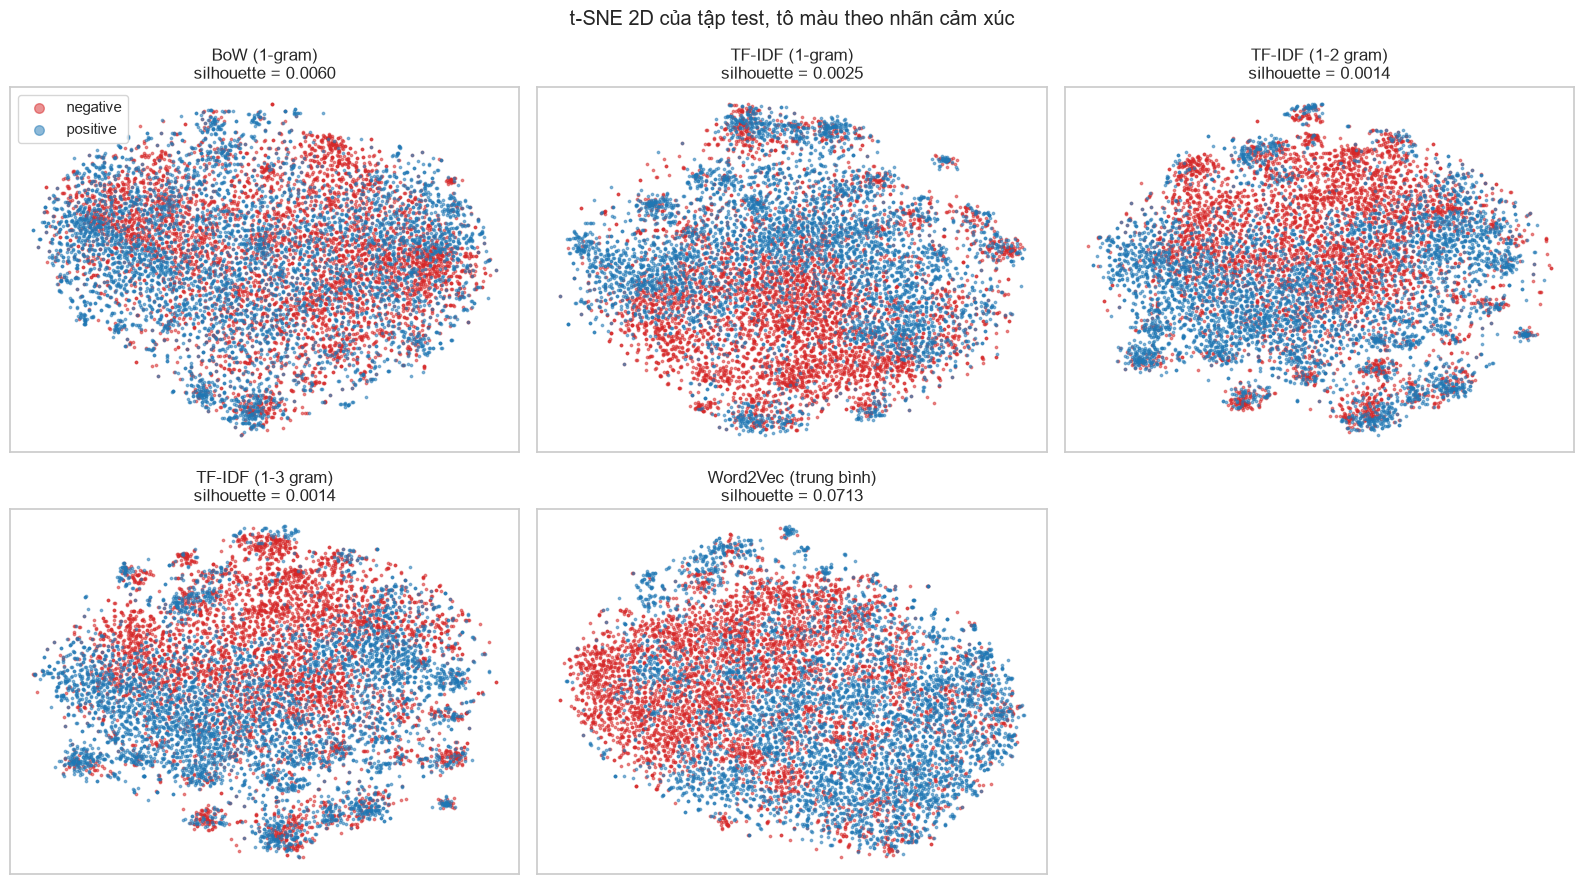

,silhouette (nhãn cảm xúc),Cohen d (6.2)
BoW (1-gram),0.0060,0.0832
TF-IDF (1-gram),0.0025,0.1242
TF-IDF (1-2 gram),0.0014,0.1309
TF-IDF (1-3 gram),0.0014,0.1306
Word2Vec (trung bình),0.0713,0.1905


In [5]:
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE

# Silhouette (nhãn cảm xúc làm nhãn cụm) trên không gian gốc, khoảng cách cosine
sil_true = {name: silhouette_score(X, y_test, metric="cosine") for name, X in REP_TEST.items()}


def tsne_embedding(name: str) -> np.ndarray:
    """SVD 50 chiều (fit trên mẫu train) cho ma trận thưa, chuẩn hóa L2, rồi t-SNE 2D."""
    X_tr, X_te = REP_TRAIN[name], REP_TEST[name]
    if sparse.issparse(X_te):
        svd = TruncatedSVD(50, random_state=config.SEED).fit(X_tr[sub_idx])
        Z = svd.transform(X_te)
    else:
        Z = X_te
    return TSNE(2, perplexity=30, init="pca", learning_rate="auto", random_state=config.SEED, n_jobs=-1).fit_transform(normalize(Z))


tsne_xy = {}
for name in REP_TEST:
    t0 = time.time()
    tsne_xy[name] = tsne_embedding(name)
    print(f"t-SNE {name}: {time.time() - t0:.0f}s | silhouette (cosine, không gian gốc) = {sil_true[name]:.4f}")
RESULTS["silhouette_true_labels"] = sil_true

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (name, xy) in zip(axes.flat, tsne_xy.items()):
    ax.scatter(xy[y_test == 0, 0], xy[y_test == 0, 1], s=3, alpha=0.5, c="tab:red", label="negative")
    ax.scatter(xy[y_test == 1, 0], xy[y_test == 1, 1], s=3, alpha=0.5, c="tab:blue", label="positive")
    ax.set_title(f"{name}\nsilhouette = {sil_true[name]:.4f}"); ax.set_xticks([]); ax.set_yticks([])
axes.flat[0].legend(markerscale=4, loc="upper left")
for ax in axes.flat[len(tsne_xy):]:
    ax.axis("off")
plt.suptitle("t-SNE 2D của tập test, tô màu theo nhãn cảm xúc")
plt.tight_layout()
plt.show()

sil_table = pd.DataFrame({"silhouette (nhãn cảm xúc)": sil_true, "Cohen d (6.2)": cos_table["Cohen d (TB)"]})
display(sil_table.round(4))

**Phân tích kết quả.**

| Biểu diễn | Silhouette (nhãn cảm xúc) | Cohen $d$ (6.2) |
|---|---|---|
| BoW (1-gram) | 0.0060 | 0.0832 |
| TF-IDF (1-gram) | 0.0025 | 0.1242 |
| TF-IDF (1-2 gram) | 0.0014 | 0.1309 |
| TF-IDF (1-3 gram) | 0.0014 | 0.1306 |
| Word2Vec (trung bình) | **0.0713** | 0.1905 |
| Sentence Transformer (6.4) | 0.0157 | 0.1016 |

- **Silhouette gần 0 ở mọi biểu diễn** (lớn nhất 0.0713): hai lớp cảm xúc chồng lấn gần hoàn toàn trong cả sáu không gian. Lý do nhất quán với 6.2: (1) sự biến thiên chủ yếu của review là chủ đề, thể loại và độ dài chứ không phải cảm xúc ($d<0.2$); (2) cảm xúc thường chỉ nằm ở một vài từ trong một văn bản dài, nên trong không gian thưa nhiều chiều khoảng cách bị chi phối bởi hàng trăm từ về chủ đề; (3) silhouette đo mức tách của các cụm theo *khoảng cách trung bình*, rất khắt khe với các cụm chồng lấn. Silhouette thấp **không có nghĩa là bài toán khó**: ở chương 5, Logistic Regression trên cùng loại biểu diễn đạt F1 trên 0.90, vì bộ phân loại có nhãn tìm được hướng phân tách mà khoảng cách không giám sát không thấy.
- **Word2Vec có silhouette cao nhất (0.0713, gấp khoảng 28 lần TF-IDF 1-gram)**, nhất quán với việc nó có Cohen $d$ lớn nhất. Hai thước đo xếp hạng không hoàn toàn giống nhau: BoW có silhouette (0.0060) cao hơn TF-IDF (0.0025) nhưng $d$ lại thấp hơn (0.0832 so với 0.1242), vì silhouette và $d$ chuẩn hóa độ phân tán theo hai cách khác nhau. Do đó ta không dựa vào một thước đo duy nhất để xếp hạng các giá trị rất nhỏ.
- **t-SNE (quan sát bằng mắt, chỉ mang tính định tính).** Với BoW, TF-IDF 1-gram, (1-2 gram) và (1-3 gram), các điểm tạo thành nhiều đám nhỏ và đậm theo chủ đề (hai màu lẫn trong từng đám), và một vùng đỏ rộng hơn ở phần giữa và dưới của TF-IDF. Với Word2Vec, các điểm negative tập trung ở phía bên trái còn positive ở phía bên phải, tức có một xu hướng chuyển dần theo cảm xúc, hợp với silhouette cao nhất. Ta không đọc khoảng cách giữa các đám hay kích thước đám trên t-SNE.

## 6.4 [Nâng cao] Sentence Transformer

Mô hình `all-MiniLM-L6-v2` (6 tầng Transformer, **384 chiều**) được huấn luyện trước bằng học tương phản trên hàng trăm triệu cặp câu để các câu cùng nghĩa có vector gần nhau; vector của một văn bản là trung bình (mean pooling) các vector token. Khác với TF-IDF, nó biểu diễn **ngữ cảnh và ngữ nghĩa** (đồng nghĩa, phủ định) chứ không chỉ sự có mặt của từ. Mô hình chỉ nhận tối đa 256 token (WordPiece), phần dài hơn bị cắt, nên ta dùng văn bản `light` (còn chữ hoa và dấu câu, đúng định dạng mô hình được huấn luyện) và đo tỉ lệ review bị cắt. Mô hình được huấn luyện trước trên dữ liệu bên ngoài và **không** fit gì trên tập của ta.

**So sánh với TF-IDF** (unigram và dải $(1,2)$) trên hai tiêu chí:
1. **K-Means ($k=2$)** trên tập test (`n_init=10`, seed cố định, vector chuẩn hóa L2): ta báo silhouette của các cụm do K-Means tìm ra và mức khớp với nhãn thật bằng **Adjusted Rand Index** (ARI; 0 là ngẫu nhiên, 1 là khớp hoàn toàn) và độ chính xác khi ghép cụm với nhãn tốt nhất. Câu hỏi: các cụm tự nhiên của biểu diễn có tương ứng với cảm xúc không?
2. **Linear SVM** (`LinearSVC`, tối thiểu hóa $\tfrac12\lVert w\rVert^2 + C\sum_i\max(0,1-y_i\,w\cdot x_i)^2$). Để so sánh công bằng, mọi biểu diễn đều huấn luyện trên **cùng 10.000 review train có nhãn** (phân tầng), chọn $C\in\{0.01,0.1,1,10\}$ bằng 5-fold CV trên 10.000 review đó, rồi đo F1 trên toàn bộ tập test. Ta cũng báo F1 của TF-IDF khi huấn luyện trên toàn bộ train làm mốc.
3. **Kiểm định McNemar** giữa hai bộ phân loại trên cùng tập test: gọi $b$ là số review mà bộ thứ nhất đúng và bộ thứ hai sai, $c$ là ngược lại. $H_0$: hai bộ có cùng tỉ lệ lỗi, tức $b$ và $c$ cùng kỳ vọng ($b\sim\text{Binomial}(b+c,\tfrac12)$); $H_1$: khác nhau; $\alpha=0.05$; dùng kiểm định nhị thức chính xác hai phía.

4. **Kiểm chứng ảnh hưởng của việc cắt văn bản.** Vì mô hình chỉ đọc 256 token đầu nên review dài bị mất phần cuối (thường là nơi người viết nêu kết luận). Ta tách tập test thành review *không bị cắt* và review *bị cắt* rồi so sánh F1 và McNemar của Sentence Transformer với TF-IDF trên từng nhóm (cùng bộ phân loại đã huấn luyện, nên chỉ là phép đo theo nhóm, không huấn luyện lại).

Cuối mục, ta minh họa bằng vài câu ngắn để xem hai biểu diễn xử lý phủ định và từ đồng nghĩa khác nhau thế nào. TF-IDF nhận câu đã bỏ stop words (đúng như pipeline chương 5, nếu để nguyên "the", "was" thì hai từ này dù hiếm trong từ vựng sẽ chi phối vector), còn embedding nhận câu tự nhiên. Đây chỉ là ví dụ minh họa, không phải kiểm định.

Mô hình: 384 chiều, độ dài tối đa 256 token; số token WordPiece / review test: TB 295, trung vị 219; tỉ lệ review test bị cắt: 41.0%


Mã hóa 19916 review mất 421s


,cos cùng lớp (TB),cos khác lớp (TB),Δ (TB),Cohen d (TB),silhouette (nhãn cảm xúc)
BoW (1-gram),0.1020,0.0967,0.0053,0.0832,0.0060
TF-IDF (1-gram),0.0283,0.0259,0.0024,0.1242,0.0025
TF-IDF (1-2 gram),0.0160,0.0146,0.0014,0.1309,0.0014
TF-IDF (1-3 gram),0.0154,0.0140,0.0014,0.1306,0.0014
Word2Vec (trung bình),0.9265,0.9207,0.0058,0.1905,0.0713
Sentence Transformer,0.2978,0.2870,0.0108,0.1016,0.0157


,silhouette của cụm K-Means,silhouette của nhãn cảm xúc,ARI so với nhãn,độ chính xác ghép cụm
TF-IDF (1-gram),0.0025,0.0025,0.0351,0.5938
TF-IDF (1-2 gram),0.0025,0.0014,0.0349,0.5935
Sentence Transformer,0.0526,0.0157,0.0171,0.5656


,C (CV),F1 CV (10k),F1 test,accuracy test
BoW (1-gram),0.01,0.8716,0.8780,0.8760
TF-IDF (1-gram),0.10,0.8818,0.8854,0.8826
TF-IDF (1-2 gram),1.00,0.8920,0.8941,0.8925
TF-IDF (1-3 gram),1.00,0.8914,0.8949,0.8933
Word2Vec (trung bình),1.00,0.8827,0.8805,0.8796
Sentence Transformer,1.00,0.8129,0.8179,0.8166
"TF-IDF (1-gram), toàn bộ train (39662)",0.10,0.9014,0.9013,0.8993
"TF-IDF (1-2 gram), toàn bộ train (39662)",1.00,0.9128,0.9129,0.9120


Kiểm định McNemar (A so với B, cùng 10.000 review huấn luyện):


,"b (A đúng, B sai)","c (A sai, B đúng)",p-value
Sentence Transformer so với TF-IDF (1-gram),509.0,1164.0,0.0
Sentence Transformer so với TF-IDF (1-2 gram),461.0,1214.0,0.0
TF-IDF (1-2 gram) so với TF-IDF (1-gram),256.0,158.0,0.0


,số review,F1 TF-IDF (1-gram),F1 TF-IDF (1-2 gram),F1 Sentence Transformer,F1 TF-IDF (1-gram) trừ F1 Sentence Transformer,McNemar p (ST so với TF-IDF 1-gram)
không bị cắt (≤ 256 token),5852.0,0.8874,0.8968,0.8475,0.0399,0.0
bị cắt (> 256 token),4064.0,0.8823,0.8902,0.7737,0.1086,0.0


,TF-IDF (1-gram),Sentence Transformer
good so với not good,0.852,0.819
good so với great,0.320,0.905
good so với terrible,0.214,0.706


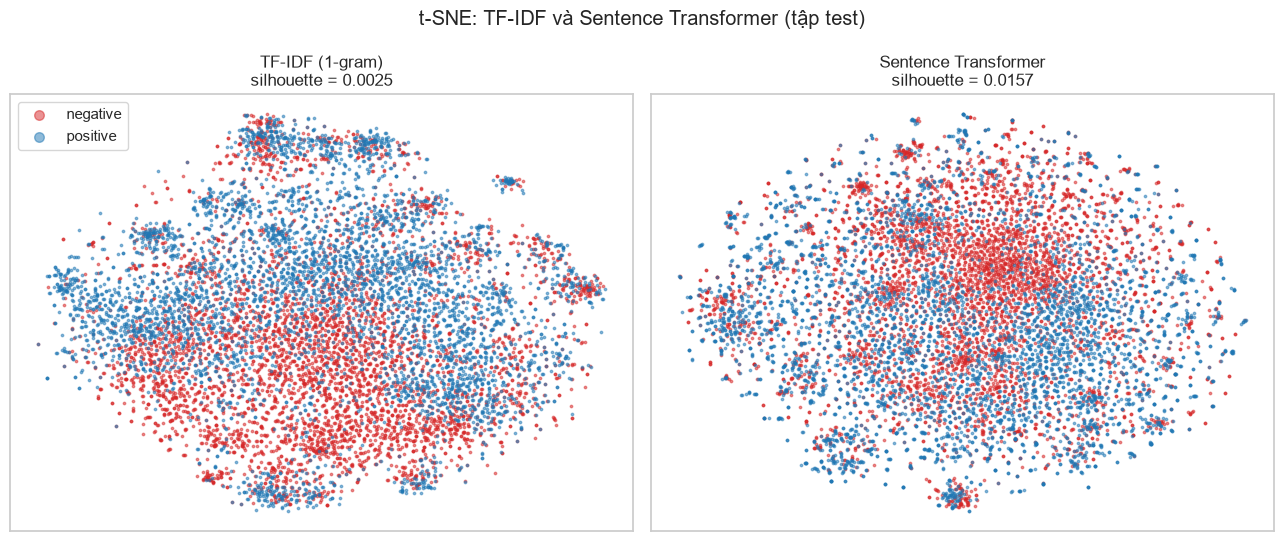

In [6]:
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"  # phải đặt trước khi import thư viện; tránh thanh tiến trình trong output
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, adjusted_rand_score, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.svm import LinearSVC
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()

st = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu")
tok_lens = np.array([len(ids) for ids in st.tokenizer(test["light"].tolist(), truncation=False)["input_ids"]])
trunc_flag = tok_lens > st.max_seq_length  # review dài hơn giới hạn của mô hình bị cắt phần cuối
n_trunc = trunc_flag.mean()
print(f"Mô hình: {st.get_sentence_embedding_dimension()} chiều, độ dài tối đa {st.max_seq_length} token; số token WordPiece / review test: TB {tok_lens.mean():.0f}, trung vị {np.median(tok_lens):.0f}; tỉ lệ review test bị cắt: {n_trunc * 100:.1f}%")
t0 = time.time()
E_test = st.encode(test["light"].tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=False)
E_sub = st.encode(train["light"].iloc[sub_idx].tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=False)
print(f"Mã hóa {len(E_test) + len(E_sub)} review mất {time.time() - t0:.0f}s")
RESULTS.update({"st_dim": int(E_test.shape[1]), "st_max_seq_length": int(st.max_seq_length), "st_truncated_pct": float(n_trunc * 100)})

# Hình học của embedding (cùng cách đo như 6.2 và 6.3)
REP_TEST["Sentence Transformer"] = E_test
st_cos = pd.DataFrame([within_subset_cosine(E_test, f) for f in folds])
st_row = {**{f"{k} (TB)": st_cos[k].mean() for k in st_cos}, "SD(Δ) giữa 10 tập": st_cos["Δ"].std(ddof=1), "SD(d) giữa 10 tập": st_cos["Cohen d"].std(ddof=1)}
sil_true["Sentence Transformer"] = silhouette_score(E_test, y_test, metric="cosine")
geometry = pd.concat([cos_table, pd.DataFrame({"Sentence Transformer": st_row}).T])
geometry["silhouette (nhãn cảm xúc)"] = pd.Series(sil_true)
display(geometry[["cos cùng lớp (TB)", "cos khác lớp (TB)", "Δ (TB)", "Cohen d (TB)", "silhouette (nhãn cảm xúc)"]].round(4))
RESULTS.update({"geometry_with_st": geometry.round(8).to_dict("index"), "silhouette_true_labels": sil_true})

# K-Means k = 2
km_rows, km_labels = {}, {}
for name in ["TF-IDF (1-gram)", "TF-IDF (1-2 gram)", "Sentence Transformer"]:
    X = normalize(REP_TEST[name])
    labels = KMeans(n_clusters=2, n_init=10, random_state=config.SEED).fit_predict(X)
    km_labels[name] = labels
    acc = max(accuracy_score(y_test, labels), 1 - accuracy_score(y_test, labels))
    km_rows[name] = {"silhouette của cụm K-Means": silhouette_score(REP_TEST[name], labels, metric="cosine"), "silhouette của nhãn cảm xúc": sil_true[name],
                     "ARI so với nhãn": adjusted_rand_score(y_test, labels), "độ chính xác ghép cụm": acc}
km_table = pd.DataFrame(km_rows).T
display(km_table.round(4))
RESULTS["kmeans"] = km_table.round(8).to_dict("index")

# Linear SVM: cùng 10.000 review có nhãn, C chọn bằng 5-fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=config.SEED)
y_sub = y_train[sub_idx]
svm_rows, svm_pred = {}, {}
E_train_rep = {"Sentence Transformer": E_sub}
for name in REP_TEST:
    X_sub = E_train_rep[name] if name in E_train_rep else REP_TRAIN[name][sub_idx]
    grid = GridSearchCV(LinearSVC(max_iter=5000, random_state=config.SEED), {"C": [0.01, 0.1, 1, 10]}, cv=cv, scoring="f1", n_jobs=5).fit(X_sub, y_sub)
    pred = grid.predict(REP_TEST[name])
    svm_pred[name] = pred
    svm_rows[name] = {"C (CV)": grid.best_params_["C"], "F1 CV (10k)": grid.best_score_, "F1 test": f1_score(y_test, pred), "accuracy test": accuracy_score(y_test, pred)}
svm_table = pd.DataFrame(svm_rows).T
# Mốc: TF-IDF huấn luyện trên toàn bộ train (khác cỡ dữ liệu huấn luyện nên không so sánh trực tiếp)
for name in ["TF-IDF (1-gram)", "TF-IDF (1-2 gram)"]:
    g = GridSearchCV(LinearSVC(max_iter=5000, random_state=config.SEED), {"C": [0.1, 1, 10]}, cv=cv, scoring="f1", n_jobs=5).fit(REP_TRAIN[name], y_train)
    p = g.predict(REP_TEST[name])
    svm_table.loc[f"{name}, toàn bộ train ({len(train)})"] = [g.best_params_["C"], g.best_score_, f1_score(y_test, p), accuracy_score(y_test, p)]
display(svm_table.round(4))
RESULTS["svm_table"] = svm_table.round(8).to_dict("index")


def mcnemar_exact(pred_a: np.ndarray, pred_b: np.ndarray, mask=None) -> dict:
    mask = np.ones(len(y_test), dtype=bool) if mask is None else mask
    ok_a, ok_b = (pred_a == y_test)[mask], (pred_b == y_test)[mask]
    b, c = int((ok_a & ~ok_b).sum()), int((~ok_a & ok_b).sum())
    return {"b (A đúng, B sai)": b, "c (A sai, B đúng)": c, "p-value": float(stats.binomtest(b, b + c, 0.5).pvalue) if b + c else 1.0}


mc_rows = {f"{a} so với {b}": mcnemar_exact(svm_pred[a], svm_pred[b]) for a, b in [("Sentence Transformer", "TF-IDF (1-gram)"), ("Sentence Transformer", "TF-IDF (1-2 gram)"), ("TF-IDF (1-2 gram)", "TF-IDF (1-gram)")]}
mc_table = pd.DataFrame(mc_rows).T
print("Kiểm định McNemar (A so với B, cùng 10.000 review huấn luyện):")
display(mc_table.round(4))
RESULTS["mcnemar"] = mc_table.round(8).to_dict("index")

# Giả thuyết giải thích điểm thấp của embedding: 41% review bị cắt ở 256 token. Kiểm chứng bằng cách tách tập test theo việc review có bị cắt không
trunc_rows = {}
for label, m in [("không bị cắt (≤ 256 token)", ~trunc_flag), ("bị cắt (> 256 token)", trunc_flag)]:
    row = {"số review": int(m.sum())}
    for name in ["TF-IDF (1-gram)", "TF-IDF (1-2 gram)", "Sentence Transformer"]:
        row[f"F1 {name}"] = f1_score(y_test[m], svm_pred[name][m])
    row["F1 TF-IDF (1-gram) trừ F1 Sentence Transformer"] = row["F1 TF-IDF (1-gram)"] - row["F1 Sentence Transformer"]
    mc = mcnemar_exact(svm_pred["Sentence Transformer"], svm_pred["TF-IDF (1-gram)"], mask=m)
    row["McNemar p (ST so với TF-IDF 1-gram)"] = mc["p-value"]
    trunc_rows[label] = row
trunc_table = pd.DataFrame(trunc_rows).T
display(trunc_table.round(4))
RESULTS["truncation_split"] = trunc_table.round(8).to_dict("index")

# Minh họa: phủ định và đồng nghĩa. TF-IDF nhận văn bản đã bỏ stop words (đúng như pipeline chương 5), embedding nhận câu tự nhiên
demo = ["the movie was good", "the movie was not good", "the movie was great", "the movie was terrible"]
demo_tfidf = ["movie good", "movie not good", "movie great", "movie terrible"]
tf_vec = VECTORIZERS["TF-IDF (1-gram)"]
Xd, Ed = normalize(tf_vec.transform(demo_tfidf)), st.encode(demo, normalize_embeddings=True)
pairs = [(0, 1, "good so với not good"), (0, 2, "good so với great"), (0, 3, "good so với terrible")]
demo_table = pd.DataFrame({"TF-IDF (1-gram)": {lab: float(Xd[i].multiply(Xd[j]).sum()) for i, j, lab in pairs},
                           "Sentence Transformer": {lab: float(Ed[i] @ Ed[j]) for i, j, lab in pairs}})
display(demo_table.round(3))
RESULTS["demo_similarity"] = demo_table.round(6).to_dict("index")

# t-SNE của embedding so với TF-IDF
xy_st = TSNE(2, perplexity=30, init="pca", learning_rate="auto", random_state=config.SEED, n_jobs=-1).fit_transform(E_test)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (title, xy) in zip(axes, [("TF-IDF (1-gram)", tsne_xy["TF-IDF (1-gram)"]), ("Sentence Transformer", xy_st)]):
    ax.scatter(xy[y_test == 0, 0], xy[y_test == 0, 1], s=3, alpha=0.5, c="tab:red", label="negative")
    ax.scatter(xy[y_test == 1, 0], xy[y_test == 1, 1], s=3, alpha=0.5, c="tab:blue", label="positive")
    ax.set_title(f"{title}\nsilhouette = {sil_true[title]:.4f}"); ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(markerscale=4, loc="upper left")
plt.suptitle("t-SNE: TF-IDF và Sentence Transformer (tập test)")
plt.tight_layout()
plt.show()

**Phân tích kết quả.**

*Hình học và K-Means* (tập test, 9.916 review; mô hình mã hóa mất 421 s cho 19.916 review):

| Biểu diễn | Silhouette (nhãn cảm xúc) | Silhouette của cụm K-Means | ARI so với nhãn | Độ chính xác ghép cụm |
|---|---|---|---|---|
| TF-IDF (1-gram) | 0.0025 | 0.0025 | 0.0351 | 59.38% |
| TF-IDF (1-2 gram) | 0.0014 | 0.0025 | 0.0349 | 59.35% |
| Sentence Transformer | 0.0157 | **0.0526** | 0.0171 | 56.56% |

*Linear SVM* (huấn luyện trên cùng 10.000 review có nhãn, $C$ chọn bằng 5-fold CV; F1 đo trên toàn bộ tập test):

| Biểu diễn | $C$ | F1 CV | F1 test | Accuracy test |
|---|---|---|---|---|
| BoW (1-gram) | 0.01 | 0.8716 | 0.8780 | 0.8760 |
| TF-IDF (1-gram) | 0.1 | 0.8818 | 0.8854 | 0.8826 |
| TF-IDF (1-2 gram) | 1 | 0.8920 | 0.8941 | 0.8925 |
| TF-IDF (1-3 gram) | 1 | 0.8914 | 0.8949 | 0.8933 |
| Word2Vec (trung bình) | 1 | 0.8827 | 0.8805 | 0.8796 |
| **Sentence Transformer** | 1 | 0.8129 | **0.8179** | 0.8166 |
| *(mốc)* TF-IDF (1-gram), toàn bộ train 39.662 | 0.1 | 0.9014 | 0.9013 | 0.8993 |
| *(mốc)* TF-IDF (1-2 gram), toàn bộ train 39.662 | 1 | 0.9128 | 0.9129 | 0.9120 |

- **Embedding ngữ nghĩa không tốt hơn TF-IDF cho phân loại tuyến tính ở đây, mà kém hơn nhiều.** Với cùng 10.000 review huấn luyện, Sentence Transformer đạt F1 test 0.8179 so với 0.8854 (TF-IDF 1-gram) và 0.8941 (TF-IDF 1-2 gram), thấp hơn 6.8 và 7.6 điểm phần trăm. McNemar (hai phía): so với TF-IDF 1-gram, $b=509$ review embedding đúng mà TF-IDF sai và $c=1164$ ngược lại, p < $10^{-8}$; so với 1-2 gram, $b=461$ và $c=1214$, p < $10^{-8}$. Cả hai bác bỏ $H_0$: tỉ lệ lỗi khác nhau có ý nghĩa, theo chiều bất lợi cho embedding. Trong các TF-IDF, 1-2 gram tốt hơn 1-gram có ý nghĩa ($b=256$, $c=158$, p = $1.7\times10^{-6}$), còn 1-3 gram gần như không thêm gì (F1 0.8949 so với 0.8941). Khi huấn luyện trên toàn bộ train, TF-IDF 1-2 gram đạt F1 test 0.9129 (cao hơn mốc Logistic Regression 0.9004 của chương 5); con số này không so sánh trực tiếp với các dòng 10.000 review vì cỡ dữ liệu huấn luyện khác nhau.
- **Word2Vec (trung bình) vượt BoW** (0.8805 so với 0.8780) và gần TF-IDF 1-gram (0.8854) chỉ với 100 chiều, nhưng không vượt TF-IDF bigram.
- **Review bị cắt là một phần lý do, không phải toàn bộ.** Có 41.0% review test dài hơn 256 token (trung bình 295, trung vị 219 token) nên mô hình không đọc phần cuối. Tách tập test theo việc review có bị cắt không, cho:

| Nhóm test | Số review | F1 TF-IDF (1-gram) | F1 Sentence Transformer | Chênh | McNemar p |
|---|---|---|---|---|---|
| không bị cắt (≤ 256 token) | 5.852 | 0.8874 | 0.8475 | 0.0399 | < $10^{-8}$ |
| bị cắt (> 256 token) | 4.064 | 0.8823 | 0.7737 | 0.1086 | < $10^{-8}$ |

  Khoảng cách F1 tăng từ 4.0 lên 10.9 điểm phần trăm (gấp khoảng 2.7 lần) khi review bị cắt, trong khi F1 của TF-IDF gần như không đổi giữa hai nhóm (0.8874 và 0.8823), nên độ khó của hai nhóm không khác nhau nhiều. Điều này ủng hộ giả thuyết cắt văn bản làm hại embedding. Tuy nhiên ngay cả ở các review ngắn, embedding vẫn kém hơn 4.0 điểm có ý nghĩa, nên cắt văn bản không giải thích hết. Một giải thích bổ sung hợp lý (chưa kiểm chứng riêng) là mô hình được huấn luyện để nắm **sự tương đồng về nghĩa/chủ đề**, trong khi cực tính cảm xúc chỉ là một thành phần nhỏ của vector sau khi trung bình hóa các token.
- **Các cụm tự nhiên của embedding không tương ứng với cảm xúc.** K-Means ($k=2$) trên embedding có silhouette của cụm cao hơn hẳn TF-IDF (0.0526 so với 0.0025, tức các cụm tách rõ hơn) nhưng khớp với nhãn cảm xúc rất kém (ARI 0.0171, độ chính xác ghép cụm 56.56%, chỉ hơn ngẫu nhiên 50% một chút), thấp hơn cả TF-IDF (ARI 0.0351, 59.4%). Nghĩa là hai cụm đó tách review theo **yếu tố khác (rất có thể là chủ đề hay thể loại, ta không kiểm chứng)** chứ không theo cảm xúc. Silhouette tính theo nhãn cảm xúc của embedding (0.0157) cao hơn TF-IDF (0.0025 đến 0.0014) nhưng vẫn rất gần 0, và Cohen $d$ của nó (0.1016 ± 0.0131) thấp hơn TF-IDF và Word2Vec.
- **Minh họa phủ định và đồng nghĩa** (ví dụ, không phải kiểm định; TF-IDF nhận câu đã bỏ stop words, embedding nhận câu tự nhiên):

| Cặp câu | cosine TF-IDF | cosine Sentence Transformer |
|---|---|---|
| "good" so với "not good" | 0.852 | 0.819 |
| "good" so với "great" | 0.320 | 0.905 |
| "good" so với "terrible" | 0.214 | 0.706 |

  Embedding nhận ra đồng nghĩa tốt hơn hẳn (good gần great: 0.905 so với 0.320 của TF-IDF), điều BoW/TF-IDF không làm được vì hai từ khác nhau là hai chiều trực giao. Nhưng **với phủ định thì cả hai đều thất bại**: "not good" vẫn rất gần "good" (0.852 với TF-IDF, 0.819 với embedding) và gần hơn nhiều so với "terrible". Vậy giả thuyết "embedding nắm được phủ định" không được ủng hộ bởi ví dụ này; nó chỉ nắm được "cùng chủ đề và cùng nhóm nghĩa".
- **Kết luận.** Với bài toán cảm xúc và bộ phân loại tuyến tính, **tần suất từ có trọng số (TF-IDF, thêm bigram) vẫn là biểu diễn mạnh nhất trong thí nghiệm này**, còn embedding tổng quát hóa ngữ nghĩa nhưng không đặc thù cho cực tính cảm xúc. Các kết luận chỉ áp dụng cho cấu hình đã thử (mô hình MiniLM không tinh chỉnh, cắt 256 token, bộ phân loại tuyến tính, 10.000 review huấn luyện); tinh chỉnh (fine-tuning) hay chia review thành nhiều đoạn có thể thu hẹp khoảng cách nhưng ta chưa thử.

## Lưu kết quả

Toàn bộ con số của chương được ghi ra `data/processed/results/` để chương báo cáo tham chiếu.

In [7]:
config.save_results("06_text_representation", RESULTS)
RESULTS

{'n_train': 39662,
 'n_test': 9916,
 'n_labeled_subset': 10000,
 'rep_table': {'BoW (1-gram)': {'số chiều': 32951.0,
   'nnz / review': 96.99969746,
   'sparsity ratio': 0.99705624,
   'thời gian fit (s)': 5.04704499},
  'TF-IDF (1-gram)': {'số chiều': 32951.0,
   'nnz / review': 96.99969746,
   'sparsity ratio': 0.99705624,
   'thời gian fit (s)': 5.75481868},
  'TF-IDF (1-2 gram)': {'số chiều': 143441.0,
   'nnz / review': 135.99455426,
   'sparsity ratio': 0.99905191,
   'thời gian fit (s)': 16.58055639},
  'TF-IDF (1-3 gram)': {'số chiều': 158199.0,
   'nnz / review': 138.97398144,
   'sparsity ratio': 0.99912152,
   'thời gian fit (s)': 21.56836104},
  'Word2Vec (trung bình)': {'số chiều': 100.0,
   'nnz / review': 100.0,
   'sparsity ratio': 0.0,
   'thời gian fit (s)': 142.36980939}},
 'w2v_vocab': 36875,
 'w2v_zero_docs_test': 0,
 'w2v_neighbors': {'good': ['decent', 'great', 'bad', 'downsides', 'godawful'],
  'bad': ['terrible', 'awful', 'horrible', 'lousy', 'good'],
  'terrib